# Figure S2

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import load_pupilbetas, DATASET_LABELS
from riskhistory.utils_pupilviz import mean_epochs_sub
import numpy as np
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

# Epoch alignment for figure S4: "start" (stimulus onset) or "response" (button press)
ALIGNMENT = "start"
ALIGNMENT_SPECS = {
    # (t_pre, t_post, x-axis label, saved filename)
    "start":    (0.0, 4.0, "Time since start of the trial (seconds)", "saved/figureS4.svg"),
    "response": (2.0, 2.0, "Time since button press (seconds)",       "saved/figureS4_response.svg"),
}

### Figure S4: 3 rows (lowest/median/highest R^2 participant) x 3 datasets
Predicted (pupil GLM) vs. observed mean pupil epoch (start-aligned, 0-4s), same reconstruction as `figures_draft_notebook/figure4_v2.ipynb`'s Panel 2, but with each row's participant picked independently per dataset (so the R^2 annotation refers to that dataset's own lowest/median/highest-fit participant, not necessarily the same subject ID across columns). Dataset names shown only on the top row; the x-axis label is shown only in the middle column of each row.

worst (equalIndifference): sub=123, R^2=0.1669
worst (equalRange): sub=76, R^2=0.1206
worst (sheng2020): sub=25, R^2=0.1439
median (equalIndifference): sub=71, R^2=0.2611
median (equalRange): sub=50, R^2=0.2899
median (sheng2020): sub=45, R^2=0.3063
best (equalIndifference): sub=75, R^2=0.4719
best (equalRange): sub=14, R^2=0.4691
best (sheng2020): sub=54, R^2=0.5306


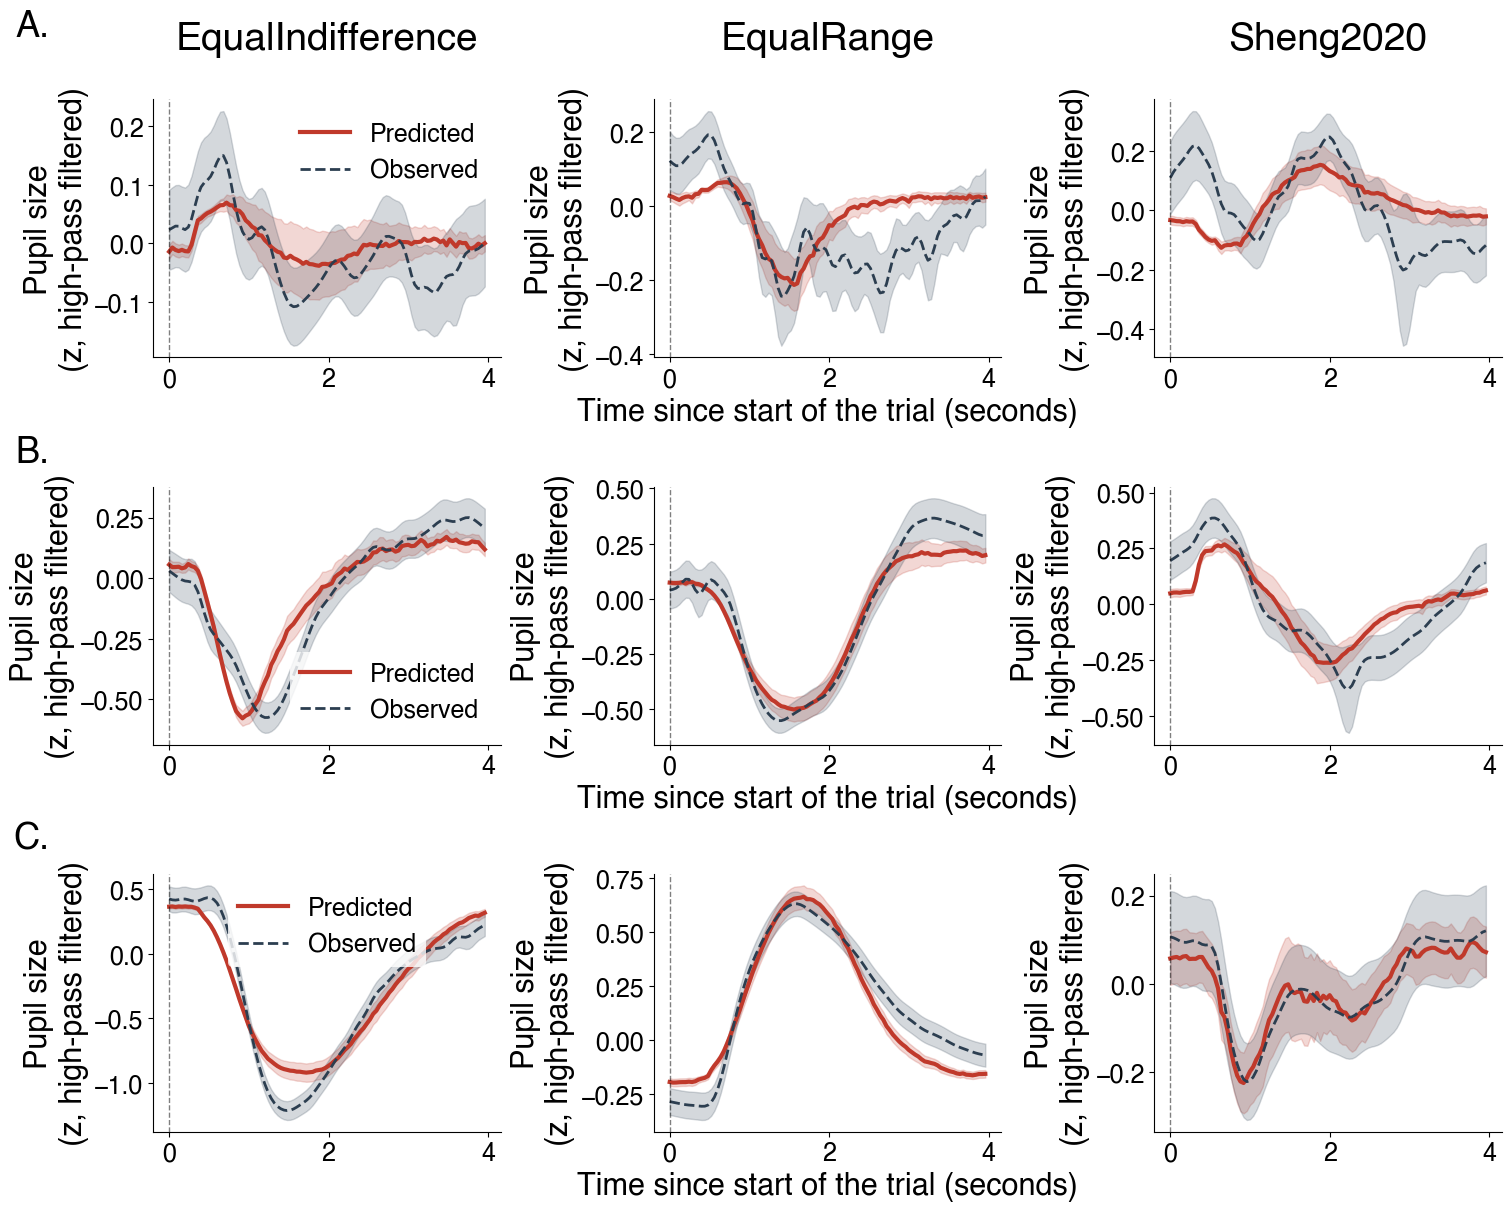

In [2]:
PRED_COLOR = "#C0392B"
OBS_COLOR = "#2C3E50"

# (mode passed to pick_subject, R^2 annotation prefix)
ROW_SPECS = [
    ("worst",  "Lowest"),
    ("median", "Median"),
    ("best",   "Highest"),
]


def pick_subject(ds_r2, mode):
    if mode == "median":
        target = ds_r2["r2"].median()
        idx = (ds_r2["r2"] - target).abs().idxmin()
    elif mode == "worst":
        idx = ds_r2["r2"].idxmin()
    elif mode == "best":
        idx = ds_r2["r2"].idxmax()
    else:
        raise ValueError(f"Unknown mode: {mode}")
    return int(ds_r2.loc[idx, "sub"]), float(ds_r2.loc[idx, "r2"])


betas_df = load_pupilbetas()
r2_per_sub = (
    betas_df.groupby(["sub", "dataset"])["r2"]
    .first()
    .reset_index()
)

t_pre, t_post, xlabel, fig_path = ALIGNMENT_SPECS[ALIGNMENT]

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 12), layout="constrained")

for row, (mode, r2_label) in enumerate(ROW_SPECS):
    for col, ds in enumerate(DATASETS):
        ax = axes[row, col]
        ds_r2 = r2_per_sub[r2_per_sub["dataset"] == ds]
        sub, r2_val = pick_subject(ds_r2, mode)
        print(f"{mode} ({ds}): sub={sub}, R^2={r2_val:.4f}")

        ep = mean_epochs_sub(sub, ds, t_pre=t_pre, t_post=t_post,
                             alignment=ALIGNMENT)
        t = ep["time_axis"]
        # Shaded bands: 95% CI of the across-trial mean (t-quantile x SEM)

        ax.fill_between(t, ep["predicted_mean"] - ep["predicted_ci95"],
                        ep["predicted_mean"] + ep["predicted_ci95"],
                        color=PRED_COLOR, alpha=0.2)
        ax.plot(t, ep["predicted_mean"], color=PRED_COLOR, linewidth=3, label="Predicted")

        ax.fill_between(t, ep["real_mean"] - ep["real_ci95"],
                        ep["real_mean"] + ep["real_ci95"],
                        color=OBS_COLOR, alpha=0.2)
        ax.plot(t, ep["real_mean"], color=OBS_COLOR, linewidth=2, linestyle="--", label="Observed")

        ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.5)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if row == 0:
            ax.set_title(f"{DATASET_LABELS.get(ds, ds)}\n")


        if col == 1:
            ax.set_xlabel(xlabel)

    axes[row, 0].set_ylabel("Pupil size\n(z, high-pass filtered)")
    axes[row, 1].set_ylabel("Pupil size\n(z, high-pass filtered)")
    axes[row, 2].set_ylabel("Pupil size\n(z, high-pass filtered)")
    axes[row, 0].legend(frameon=True, facecolor="white", edgecolor="none")

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
for row, label in enumerate(["A.", "B.", "C."]):
    y = 1.35 if row == 0 else 1.2
    axes[row, 0].text(-0.3, y, label, transform=axes[row, 0].transAxes,
                      fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()